In [1]:
from anemone.forwards import Forward
from anemone.inversion import Resistivity

In [2]:
import torch
from anemone.experiment import Loop, Receiver, Waveform, ButterworthFilter, FilterChain
from anemone.physics import mpa2colecole
from anemone import constants as c
sq = Loop.square(40)
rx = Receiver()

waveform = Waveform.example()

ainv_dat = torch.tensor([[9.350E-06,  1.745393E-04],
                        [1.145E-05,  1.303665E-04],
                        [1.458E-05,  9.897802E-05],
                        [1.822E-05,  7.424845E-05],
                        [2.255E-05,  5.230275E-05],
                        [2.867E-05,  3.168347E-05],
                        [3.595E-05,  1.788651E-05],
                        [4.460E-05,  9.527986E-06],
                        [5.660E-05,  4.206293E-06],
                        [7.070E-05,  1.706046E-06],
                        [8.630E-05,  5.354002E-07],
                        [1.071E-04, -5.975600E-08],
                        [1.381E-04, -2.894035E-07],
                        [1.748E-04, -3.310659E-07],
                        [2.174E-04, -2.693721E-07],
                        [2.775E-04, -1.754609E-07],
                        [3.515E-04, -1.040936E-07],
                        [4.385E-04, -6.107881E-08],
                        [5.575E-04, -3.306694E-08],
                        [7.035E-04, -1.822600E-08]], dtype=torch.float64)



ainv_dbdt = ainv_dat[:, 1].clone()
t0 = ainv_dat[:, 0].clone()
not_zero_xing = torch.ones_like(ainv_dat[:, 0], dtype=torch.bool)
not_zero_xing[torch.searchsorted(t0, torch.tensor([1.071e-4]))-1] = False


fwr = Forward.mpa(sq, rx, t0, waveform=waveform)

rho=  torch.tensor([5.000e+02,5.000e+02,5.000e+02,8.000e+02,8.000e+02,5.000e+02,5.000e+02,5.000e+02,5.000e+02,2.000e+02,2.000e+02,5.000e+02,5.000e+02,5.000e+02,5.000e+02,5.000e+02,5.000e+02,8.000e+02,8.000e+02,5.000e+02])
phi = torch.tensor([2.000e+02,2.000e+02,2.000e+02,2.000e+02,2.000e+02,5.000e+02,5.000e+02,5.000e+02,5.000e+02,8.000e+02,8.000e+02,8.000e+02,8.000e+02,8.000e+02,8.000e+02,8.000e+02,8.000e+02,8.000e+02,8.000e+02,8.000e+02])/1e3
tau = torch.tensor([1.000e-04,1.000e-04,1.000e-04,2.000e-04,2.000e-04,1.000e-04,1.000e-04,9.000e-04,9.000e-04,9.000e-04,1.000e-04,1.000e-04,1.000e-04,1.000e-04,1.000e-04,1.000e-04,1.000e-04,1.000e-04,1.000e-04,1.000e-04])
C =   torch.tensor([6.000e-01,6.000e-01,4.000e-01,4.000e-01,6.000e-01,6.000e-01,6.000e-01,6.000e-01,6.000e-01,3.000e-01,3.000e-01,3.000e-01,3.000e-01,6.000e-01,6.000e-01,6.000e-01,6.000e-01,6.000e-01,6.000e-01,6.000e-01])
thick=torch.tensor([1.000e+00, 1.177e+00, 1.386e+00, 1.632e+00, 1.922e+00, 2.263e+00, 2.665e+00, 3.138e+00, 3.695e+00, 4.351e+00, 5.124e+00, 6.034e+00, 7.105e+00, 8.366e+00, 9.851e+00, 1.160e+01, 1.365e+01, 1.608e+01, 1.893e+01])

# rho,m_cc,tau_cc,C = mpa2colecole(rho, phi, tau, C)
dbdt = fwr(rho, phi,tau, C, thick)

weight = fwr.H2t.mean(0)
weight /= weight.sum()

rho_mean = -1./(fwr.sigma.real @ weight).squeeze()
rho_mean = Resistivity([rho_mean, thick])

fwr0 = Forward(sq, rx, t0, waveform=waveform)
dbdt0 = fwr0(*rho_mean.mod)

array([<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>,
       <Axes: title={'center': 'phi'}>, <Axes: title={'center': 'tau'}>,
       <Axes: title={'center': 'c'}>], dtype=object)

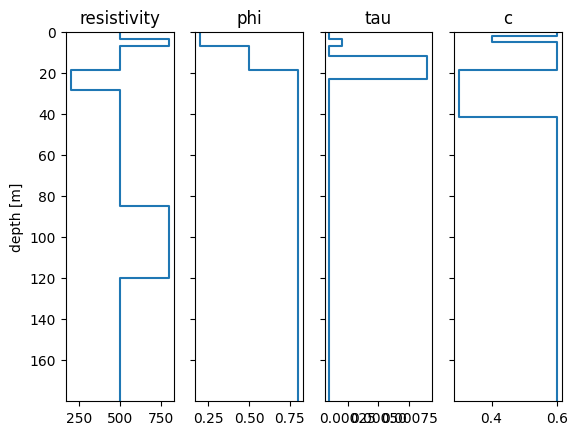

In [3]:
from anemone.inversion import MPA

m_true = MPA([rho, phi, tau, C, thick])
m_true.plot()

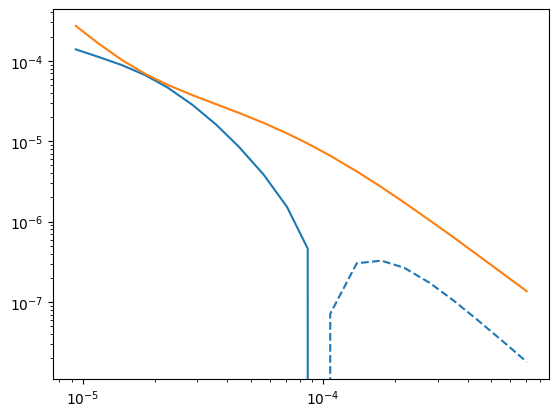

In [4]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.loglog(fwr.times, dbdt)
plt.loglog(fwr.times, -dbdt, 'C0--')

plt.loglog(fwr.times, dbdt0)
plt.loglog(fwr.times, -dbdt0, 'C0--')


In [5]:
import torch
from scipy.linalg import block_diag
import numpy as np
from nosj import nosj
from typing import List

@nosj
class BaseModel:
    values: List[torch.Tensor]
    names:  List[str]
    lower_bounds: List[torch.Tensor] = None
    upper_bounds: List[torch.Tensor] = None
    free_params:  List[bool] = None
    description: str = "Base model class for inversion models"
    log_scale: bool = False

    def __post_init__(self):
        if not isinstance(self.values, list): self.values = [self.values]
        if self.free_params is None: self.free_params = [True]*len(self.values)
        if self.names is None: self.names  = ['physical_property_{}'.format(i) for i in range(len(self.values))]
        if not isinstance(self.names, list): self.names = [self.names]
        
        if self.lower_bounds is None : self.lower_bounds = [-1.*torch.ones_like(val)*torch.inf for val,free in zip(self.values, self.free_params)]
        if self.upper_bounds is None : self.upper_bounds = [    torch.ones_like(val)*torch.inf for val,free in zip(self.values, self.free_params)]
        if not isinstance(self.lower_bounds, list): self.lower_bounds = [self.lower_bounds]
        if not isinstance(self.upper_bounds, list): self.upper_bounds = [self.upper_bounds]
        if not isinstance(self.lower_bounds[0], torch.Tensor): 
            self.lower_bounds = [torch.ones_like(val)*bnd for val,bnd in zip(self.values, self.lower_bounds)]
        if not isinstance(self.upper_bounds[0], torch.Tensor):
            self.upper_bounds = [torch.ones_like(val)*bnd for val,bnd in zip(self.values, self.upper_bounds)]
            
        self.dim          = len(self.values[0].shape)
        self.pslice       = []
        self.pshape       = []
        

        counter=0
        for val, free in zip(self.values, self.free_params):
            if free:
                self.pslice.append(slice(counter, counter+len(val.flatten())))
                self.pshape.append(val.shape)
                counter += len(val.flatten())
        self.lbnds = self.vectorize(self.lower_bounds)
        self.ubnds = self.vectorize(self.upper_bounds)
            
        self.n_params = len(self.vec)
        self.n_ptypes = sum([int(free) for free in self.free_params])

    def set_device(self, device):
        self.device=device
        for var_name in vars(self):
            var = getattr(self, var_name)
            if torch.is_tensor(var):
                setattr(self, var_name, var.to(device))
            elif isinstance(var, list):
                for i, v in enumerate(var):
                    if torch.is_tensor(v):
                        var[i] = v.to(device)


    @property
    def mod(self):
        """ the reason for return modelize of the vector representation is to accomodate models with fixed parameters
            the many layer smooth models for example have fixed thicknesses, so modelize function will return the thickness as well.
            if self.values is used, the thickness will not be included.
        """
        return self.modelize(self.vec)
    
    @property
    def vec(self):
        return self.vectorize(self.values)
    
    def vectorize(self, list_of_arrays):
        res = torch.concatenate([v for v,free in zip(list_of_arrays, self.free_params) if free])
        if self.log_scale: res = torch.log(res)
        return res

    def modelize(self, mvec):
        if self.log_scale: mvec = torch.exp(mvec)
        assert len(mvec) == self.n_params, 'incorrect number of parameters in update vector'

        model = []
        i_m = 0
       
        for i_p, free in enumerate(self.free_params):
            shp = self.values[i_p].shape
            if free:
                pslice,pshape = self.pslice[i_m], self.pshape[i_m]
                model.append(mvec[pslice].reshape(pshape+(-1,)).squeeze())
                i_m += 1
            else:
                model.append(self.values[i_p])

        return model

    def make_physical(self, mvec):
        new_mvec = torch.clamp(mvec, self.lbnds, self.ubnds)
        return new_mvec

    def H(self, **kwargs):
        Hs = block_diag(*[self.H1d(val) for val,free in zip(self.values, self.free_params) if free])
        return torch.from_numpy(Hs)

    def H1d(self, values):
        H = (np.eye(len(values))-np.eye(len(values), k=1))[:-1]
        return H
    
    def update_model(self, m):
        m = self.make_physical(m)
        self.update_values(m)
        return self

    def update_values(self, vec):
        assert len(vec) == len(self.vec), 'incorrect number of parameters in update vector'
        if self.log_scale:
            vec = torch.exp(vec)
        i_m = 0
        for i_p, free in enumerate(self.free_params):
            shp = self.values[i_p].shape
            if free:
                self.values[i_p] = vec[i_m:i_m+len(self.values[i_p].flatten())].reshape(shp)
            i_m += len(self.values[i_p].flatten())
        return self

    def check_physical(self):
        for i in range(len(self.values)):
            self.values[i] = np.clip(self.values[i], self.lower_bounds[i], self.upper_bounds[i])*1.
        return self
    
    def value_z_plot(self, value):
        if 'thickness' in self.names:
            thk = self.values[self.names.index('thickness')].cpu()
        else:
            thk = self.thickness.cpu()
        v = self.values[self.names.index(value)]
        z1 = np.cumsum(thk.numpy())
        z2 = np.zeros((len(z1)+1,2))
        z2[1:,0]=z1
        z2[:-1,1]=z1
        z2[-1,1] = z1.max()*1.5
        v2 = np.repeat(v.numpy(), 2).T
        
        return v2.flatten(), z2.flatten()

    
    def plot(self, axs=None, **kwargs):
        n_params = len(self.values)
        if 'thickness' in self.names:
            thk = self.values[self.names.index('thickness')].cpu()
        else:
            thk = self.thickness.cpu()
        if axs is None:
            from matplotlib.pyplot import subplots
            fig,axs = subplots(1,n_params-1, sharey=True)
            if not isinstance(axs, np.ndarray):axs = [axs]
        for v,ax,pname in zip(self.values, axs, self.names):
            if pname != 'thickness':
                v2,z2 = self.value_z_plot(pname)
                ax.plot(v2.flatten(), z2.flatten(), **kwargs)
                ax.set_title(pname)
                ax.set_ylim(z2.max(), z2.min())
        axs[0].set_ylabel('depth [m]')
        return axs
    
    @classmethod
    def smooth(cls, values, z_bounds, **kwargs):
        n_layers = len(z_bounds)+1
        z = z_bounds
        thickness = torch.diff(z_bounds, prepend=torch.zeros(1, dtype=z_bounds.dtype))
        if not isinstance(values, list): values = [values]
        values += [thickness]
        free_params = kwargs.get('free_params', [True]*len(values))
        free_params[-1] = False  # fix thicknesses
        kwargs['free_params'] = free_params
        return cls(values, **kwargs)
    
    @classmethod
    def few_layers(cls, values, thickness, **kwargs):
        class FewLayersModel(cls):
            n_layers = len(thickness)+1
            def __init__(self, values, **kwargs):
                super().__init__(values, **kwargs)
                if 'thickness' not in self.names:
                    self.names.append('thickness')
                    self.values.append(thickness)

        if not isinstance(values, list): values = [values]
        values += [thickness]
        return FewLayersModel(values, **kwargs)

from dataclasses import field


In [6]:

class ComplexResForward(Forward):
    def __call__(self, rho_r, rho_i, thick):
        self.rho = rho_r[..., None, None] + 1j*rho_i[..., None, None]
        self.thick = thick
        return self.forward()*c.mu0

@nosj
class ComplexRes(BaseModel):
    log_scale: bool = True
    def __init__(self, values, **kwargs):
        res_bnds = kwargs.pop('res_bnds', (1,    1e3))
        resi_bnds = kwargs.pop('resi_bnds', (1e-9, 1e3))
        thk_bnds = kwargs.pop('thk_bnds', (1,    100))
        max_step = kwargs.pop('max_step', torch.log(torch.tensor([3,3,1.6])))
        min_step = kwargs.pop('min_step', torch.log(torch.tensor([1.1, 1.1, 1.03])))

        upper_bounds = [torch.ones_like(val)*bnds[1] for val,bnds in zip(values, [res_bnds, resi_bnds])]
        lower_bounds = [torch.ones_like(val)*bnds[0] for val,bnds in zip(values, [res_bnds, resi_bnds])]
        if not isinstance(values, list):
            values = [values]
        names = ['res_r', 'res_i']
        if len(values) == 3:
            upper_bounds.append(torch.ones_like(values[-1])*thk_bnds[1])
            lower_bounds.append(torch.ones_like(values[-1])*thk_bnds[0])
            names.append('thickness')
        kwargs['names'] = names
        kwargs.setdefault('lower_bounds', lower_bounds)
        kwargs.setdefault('upper_bounds', upper_bounds)
        super().__init__(values, **kwargs)
        self.max_step = max_step
        self.min_step = min_step

In [7]:
cfwr = ComplexResForward(sq, rx, t0, waveform=waveform)

In [10]:
dbdt1 = cfwr(rho, rho+torch.linspace(-1., 1., len(rho)), thick)

n_mods = 25

rho2d = rho[:,None]*torch.ones(n_mods)[None,:]
rho2d = rho2d + 1j*rho[:,None]*0.1*torch.linspace(-2,2,n_mods)[None,:]

dbdt1 = cfwr(rho2d.real, rho2d.imag, thick)

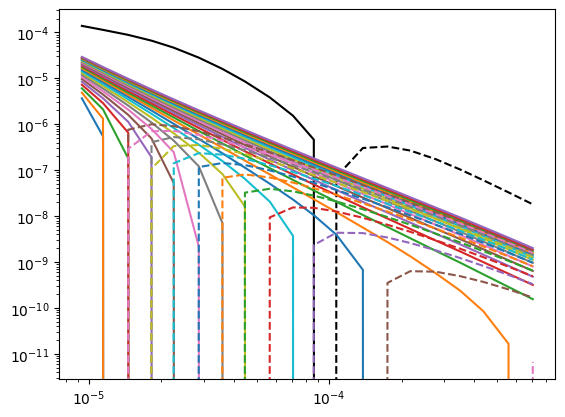

In [11]:
plt.figure()
plt.loglog(fwr.times,  dbdt, 'k')
plt.loglog(fwr.times, -dbdt, 'k--')
plt.loglog(fwr.times, dbdt1.T)
plt.loglog(fwr.times, -dbdt1.T, '--')

In [12]:
from anemone.inversion import Inversion

In [13]:
tmp = -1./(fwr.sigma @ (weight+0j)).squeeze()
crho = ComplexRes([tmp.real,tmp.imag, thick])

In [14]:
res_start = ComplexRes.smooth([torch.ones(31)*10., torch.ones(31)*1e-2], torch.cumsum(torch.linspace(1., 5., 30), 0))
inv = Inversion(dbdt, dbdt*0.03, res_start, cfwr)
inv.vertical_smoothness = 2.

In [15]:
resmod = inv.invert()

C:\Users\au646858\OneDrive - Aarhus Universitet\Documents\_repositories\anemone\src\anemone\inversion\inversion.py:262: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  diag_GTG = torch.tensor(self.GtG.diagonal())
C:\Users\au646858\OneDrive - Aarhus Universitet\Documents\_repositories\anemone\src\anemone\inversion\inversion.py:329: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  dm = sp.sparse.linalg.spsolve(Aown, self._r_data)


001	Data misfit:	572.77	Vertical misfit:	0.00	Total misfit:	286.38	Step size:	1.10	Last iteration time:	0.06

002	Data misfit:	470.85	Vertical misfit:	0.01	Total misfit:	235.43	Step size:	1.10	Last iteration time:	1.22

003	Data misfit:	389.29	Vertical misfit:	0.01	Total misfit:	194.64	Step size:	1.28	Last iteration time:	1.28

004	Data misfit:	264.87	Vertical misfit:	0.03	Total misfit:	132.44	Step size:	1.28	Last iteration time:	1.15

005	Data misfit:	179.94	Vertical misfit:	0.05	Total misfit:	89.97	Step size:	1.28	Last iteration time:	1.45

006	Data misfit:	110.13	Vertical misfit:	0.06	Total misfit:	55.06	Step size:	1.46	Last iteration time:	1.19

007	Data misfit:	87.42	Vertical misfit:	0.08	Total misfit:	43.71	Step size:	1.46	Last iteration time:	1.31

008	Data misfit:	75.03	Vertical misfit:	0.11	Total misfit:	37.52	Step size:	1.46	Last iteration time:	1.19

009	Data misfit:	64.87	Vertical misfit:	0.17	Total misfit:	32.44	Step size:	1.65	Last iteration time:	1.20

010	Data misfit:	5

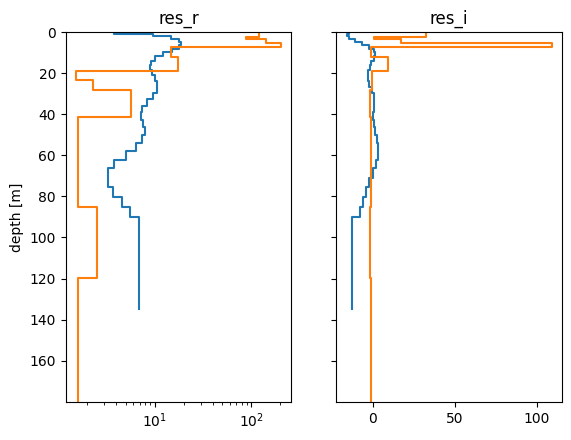

In [16]:
axs=resmod.plot()
crho.plot(axs=axs)
axs[0].set_xscale('log')

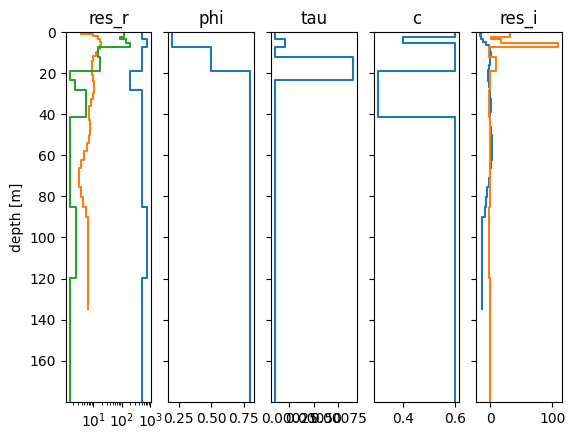

In [17]:
fig,axs = plt.subplots(1,5, sharey=True)
m_true.plot(axs=axs[:-1])
resmod.plot(axs=axs[::4])
crho.plot(axs=axs[::4])
axs[0].set_xscale('log')


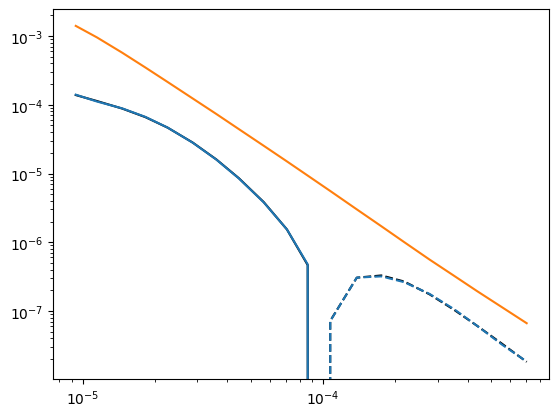

In [19]:
plt.figure()
plt.loglog(fwr.times,  dbdt, 'k-')
plt.loglog(fwr.times, -dbdt, 'k--')

d_pred = cfwr(*resmod.mod)
plt.loglog(fwr.times,  d_pred, 'C0-')
plt.loglog(fwr.times, -d_pred, 'C0--')


d_pred = fwr0(resmod.mod[0], resmod.mod[-1])
plt.loglog(fwr.times,  d_pred, 'C1-')
plt.loglog(fwr.times, -d_pred, 'C1--')
